# Illegal Maritime Activity: AIS dark periods of Russian fishing vessels (2024)

Data sprint on illicit activities and hybrid threats at sea, University of Copenhagen, February 2025.

**Question.** Fishing vessels are required to transmit their position through AIS. Which Russian-flagged fishing vessels in Danish AIS coverage switched their transponder off, for how long, and where?

**Definition.** A *dark period* is a gap between two consecutive AIS messages of the same vessel that is **longer than 2 hours** (to allow for technical drop-outs) and **shorter than 1 day** (to avoid docked vessels or vessels that left coverage). The last message before the gap marks where the AIS went **off**; the first message after it marks where it came back **on**.

In [1]:
import sys
sys.path.insert(0, "../src")  # make the project package importable

import pandas as pd
from illegal_maritime_activity import classify_mmsi, detect_dark_periods, flag_dark_events, load_ais
from illegal_maritime_activity.plotting import (
    load_basemaps, plot_dark_events, plot_gap_durations, plot_positions_by_flag,
)

## 1. Data

The source is the Danish Maritime Authority AIS data for 2024, resampled to one message every 30 minutes. The raw file is too large to share; `scripts/prepare_data.py` reproduces the two filtering steps from it:

1. keep vessels whose ship type is *fishing*;
2. keep one flag state, identified by the first three digits of the MMSI (the Maritime Identification Digits): `273` for Russia, `219`/`220` for Denmark.

Comparing flags rests on the assumption that vessels fishing near their home waters are more likely to be genuine fishing vessels. Here we load the Russian subset.

In [2]:
df = load_ais("../data/processed/russian_fishing_vessels_2024.csv")
df = df.drop(columns=["Status"], errors="ignore")  # sprint labels, recomputed below
print(f"{len(df):,} AIS messages from {df['MMSI'].nunique()} vessels")
df[["MMSI", "Name", "# Timestamp", "Latitude", "Longitude", "Navigational status", "SOG", "Destination"]].head()

9,669 AIS messages from 83 vessels


,MMSI,Name,# Timestamp,Latitude,Longitude,Navigational status,SOG,Destination
5003969,273258100,STARYY ARBAT,2024-01-01 00:30:00,55.676642,12.683768,Under way using engine,9.2,SAINT PETERSBURG
5003970,273258100,STARYY ARBAT,2024-01-01 01:00:00,55.605432,12.696977,Under way using engine,8.5,SAINT PETERSBURG
5003971,273258100,STARYY ARBAT,2024-01-01 01:30:00,55.526482,12.694373,Under way using engine,11.7,SAINT PETERSBURG
5003972,273258100,STARYY ARBAT,2024-01-01 02:00:00,55.431718,12.660500,Under way using engine,11.8,SAINT PETERSBURG
5003973,273258100,STARYY ARBAT,2024-01-01 02:30:00,55.335237,12.634585,Under way using engine,11.7,SAINT PETERSBURG


Where were these vessels during the busiest month? The map uses the extent of Danish waters from the sprint maps.

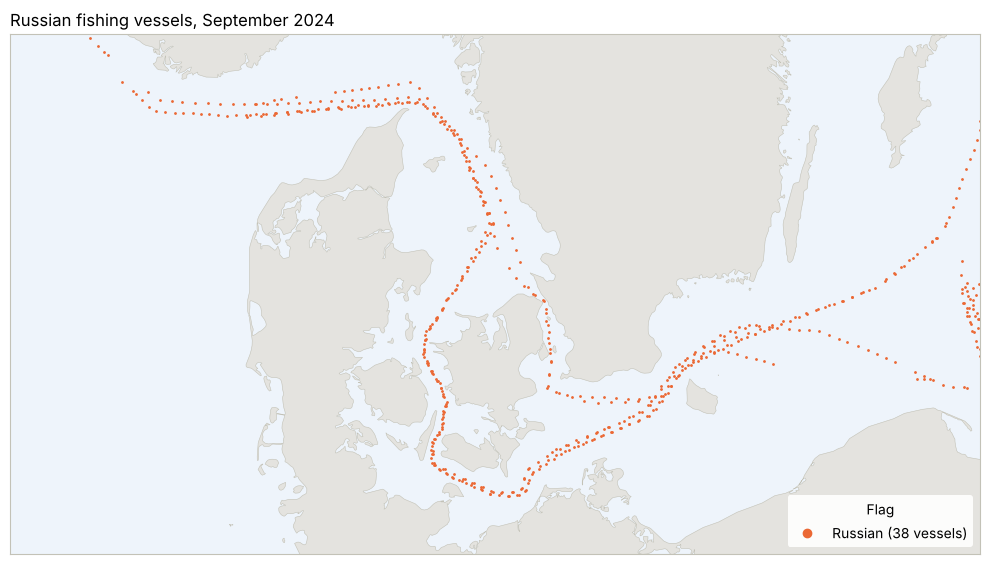

In [3]:
df["country"] = df["MMSI"].apply(classify_mmsi)
fig, ax = plot_positions_by_flag(df, month=9, title="Russian fishing vessels, September 2024")

## 2. Detecting dark periods

For each vessel, messages are sorted by time and compared with the previous one. Gaps between 2 h and 24 h become dark periods. The straight-line distance between the two positions, and the average speed needed to cover it, give a first sense of how far a vessel moved while dark. Both are left empty when AIS reports the position as unavailable (latitude 91°).

In [4]:
events = detect_dark_periods(df, min_gap=pd.Timedelta(hours=2), max_gap=pd.Timedelta(days=1))
print(f"{len(events)} dark periods across {events['MMSI'].nunique()} vessels, "
      f"{events['distance_km'].isna().sum()} without a known position")
events.head()

211 dark periods across 48 vessels, 47 without a known position


,on_row,MMSI,IMO,Name,off_time,on_time,gap_hours,off_lat,off_lon,on_lat,on_lon,off_nav_status,on_nav_status,distance_km,implied_speed_kn
0,6715778,273212100,8415574,OSVEYSKOYE,2024-11-14 21:30:00,2024-11-15 02:00:00,4.5,57.862315,9.301260,57.834685,8.605412,Under way using engine,Under way using engine,41.290074,4.954413
1,6715781,273212100,8415574,OSVEYSKOYE,2024-11-15 04:30:00,2024-11-15 08:30:00,4.0,57.818148,8.154645,57.714590,7.653473,Under way using engine,Under way using engine,31.876205,4.302943
2,6555525,273212350,8845652,RUBIN,2024-07-21 04:30:00,2024-07-21 15:30:00,11.0,91.000000,0.000000,54.686408,20.252108,Moored,Moored,NaN,NaN
3,6555527,273212350,8845652,RUBIN,2024-07-21 16:00:00,2024-07-21 18:30:00,2.5,54.686428,20.252115,54.686422,20.252115,Moored,Moored,0.000667,0.000144
4,6555544,273212350,8845652,RUBIN,2024-09-07 04:30:00,2024-09-07 07:00:00,2.5,91.000000,0.000000,54.923785,19.686833,Unknown value,Under way using engine,NaN,NaN


In [5]:
per_vessel = (events.groupby(["MMSI", "Name"])
              .agg(dark_periods=("gap_hours", "size"),
                   total_dark_hours=("gap_hours", "sum"),
                   longest_gap_hours=("gap_hours", "max"))
              .sort_values("dark_periods", ascending=False))
per_vessel.head(10)

,,dark_periods,total_dark_hours,longest_gap_hours
MMSI,Name,,,
273450640,MRTK-0770,20,172.5,23.5
273297610,MRTK-0777,15,119.0,19.0
273291590,VSESLAV,14,146.5,22.0
273212350,RUBIN,13,100.5,17.0
273612200,MPTK-0850,13,109.0,21.5
273437740,MRTK-0857,9,75.5,21.5
273453540,MRTK-1716,9,77.0,20.5
273219390,AGAT,8,67.5,14.0
273458630,VAIVARA,8,70.0,22.5


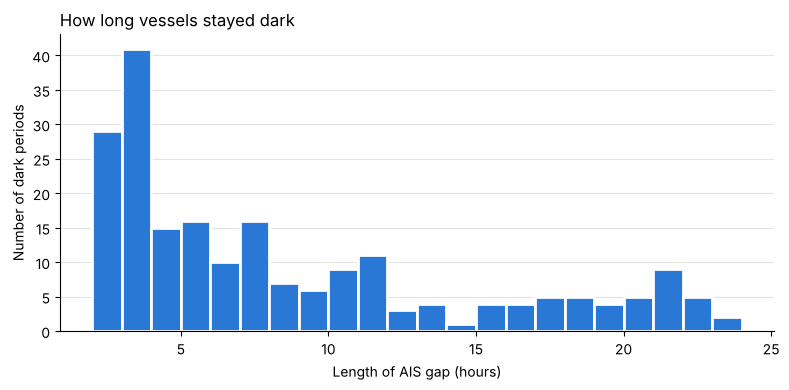

In [6]:
fig, ax = plot_gap_durations(events)

## 3. Where vessels went dark

Circles mark where the AIS was switched off and triangles where it came back on.

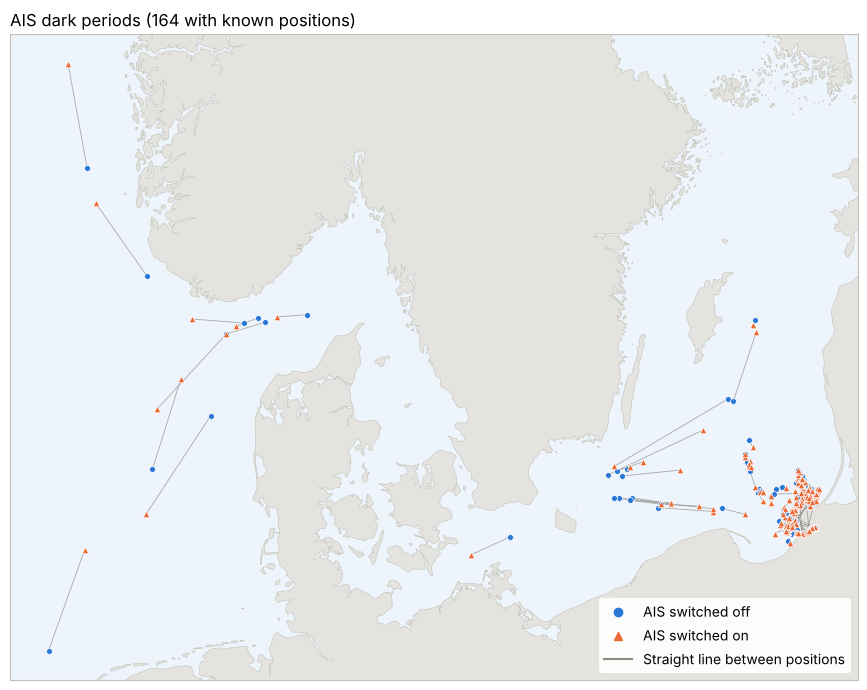

In [7]:
waters, cables = load_basemaps()  # optional layers; None if not downloaded
fig, ax = plot_dark_events(events, waters, cables)

## 4. Labelling full tracks

`flag_dark_events` labels every message, so whole tracks can be drawn with the dark moments highlighted. A message that ends one dark period and starts the next is labelled `on/off`.

In [8]:
flagged = flag_dark_events(df, events)
flagged["Status"].value_counts()

Status
Regular    9264
off         194
on          194
on/off       17
Name: count, dtype: int64

## Limitations and next steps

- With 30-minute data a gap only means that no message reached a Danish receiver. Reception is weaker far from the coast, so a gap is an indicator, not evidence of deliberate switching off.
- The 2 h / 24 h window is a judgement call; `scripts/run_analysis.py --min-gap --max-gap` tests other values.
- **Next step:** estimate the area each vessel could have reached while dark (last position, gap length, typical speed) and intersect it with submarine cables and offshore wind farms.